# 02. Tuning dan penilaian tracker di CCTV PT SRP

Semua tracker (Lite, ByteTrack, OC-SORT, BoT-SORT, TrackTrack, FastTrack) diberi kesempatan yang sama: parameternya disetel di klip **tuning**, lalu dinilai di klip **penilaian** dari kamera yang tidak dipakai untuk tuning. Hasil terbaiknya adalah `Lite tuned` di `configs/tracker_tuned.json`.

**Cara menilai tanpa label manusia.** Video CCTV belum punya label ID. Sebagai gantinya, tiap tracker dibandingkan dengan dua tracker "mahal" (ByteTrack dan OC-SORT) yang dijalankan pada 12,5 FPS. Di FPS setinggi itu gerak antar frame kecil, jadi ID-nya relatif stabil. Kesepakatan antara kedua referensi menjadi batas atas wajar. Angkanya mengukur "seberapa dekat ke tracking mahal", belum akurasi mutlak. Untuk akurasi mutlak dibutuhkan video ground truth.

| Bagian | Isi |
|---|---|
| 1 | Pilih klip tuning dan penilaian, jalankan detektor sekali per klip, simpan cache deteksi |
| 2 | Dua referensi dan seberapa jauh keduanya sepakat |
| 3 | Tuning tiap tracker (anggaran sama) |
| 4 | Penilaian di klip kamera test, per FPS |
| 5 | Ablasi: bagian Lite mana yang benar-benar membantu |
| 6 | Perkiraan kapasitas kamera |
| 7 | Simpan hasil ke `configs/tracker_tuned.json` |

**Butuh:** detektor `models/dfine-n-1248x704-commercial-v3.onnx`, folder video PT SRP (`Dataset_Momen_PPE_Anonim`, berisi `momen_log.csv`). Cache deteksi dari repo `nana-detect-ppe` (`outputs/cache/`) dipakai otomatis kalau ada, jadi detektor tidak perlu dijalankan ulang.

**Waktu:** QUICK sekitar 5 menit. Penuh: cache deteksi sekitar 1 menit per klip (sekali saja), tuning 5 sampai 10 menit.

Hasil tersimpan di `experiments/02_tuning_cctv/<waktu>/`.

In [12]:
# Cek Python yang dipakai notebook. Harus .venv milik repo ini.
import sys, importlib.util
print("Python:", sys.executable)
missing = [m for m in ('numpy', 'scipy', 'pandas', 'matplotlib', 'cv2', 'onnxruntime', 'ultralytics') if importlib.util.find_spec(m) is None]
if ".venv" not in sys.executable or missing:
    raise RuntimeError(
        "Notebook belum memakai .venv proyek" + (f" (paket tidak ada: {', '.join(missing)})" if missing else "") + ".\n"
        "Jalankan `uv sync` di folder repo, lalu di VS Code: klik nama kernel di kanan atas > Select Another Kernel > "
        "Python Environments > .venv (object-tracking), atau Enter interpreter path: "
        "~/Documents/GitHub/object-tracking/.venv/bin/python"
    )
print("ok, semua paket ada")

Python: /Users/rdrusdiati/Documents/GitHub/object-tracking/.venv/bin/python
ok, semua paket ada


## 0. Pengaturan

In [13]:
import os, sys, json, time, platform, warnings
from pathlib import Path
from datetime import datetime
from dataclasses import replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)
REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "src"))

from object_tracking.reference_eval import build_det_cache, save_cache, load_cache, compare, capacity
from object_tracking.video_io import decode_cost
from object_tracking.tune import references, search
from object_tracking.zoo import PRESETS, run_spec, save_tuned, load_tuned, TUNED_PATH

# ===================== ubah di sini =====================
VIDEO_DIR  = Path(os.environ.get("OT_VIDEO_DIR", Path.home() / "PPE - PT SRP" / "Dataset_Momen_PPE_Anonim"))
DET_MODEL  = REPO / "models" / "dfine-n-960x540-stride-8.onnx"
QUICK      = os.environ.get("OT_QUICK", "0") == "1"   # True = klip lebih pendek dan tuning lebih sedikit
TEST_CLIPS = ["v02_momen_013", "v12_momen_001", "v07_momen_003", "v01_momen_037", "v10_momen_003"]  # kamera test
CLIP_SEC   = 20 if QUICK else 60      # detik pertama tiap klip yang dipakai
REF_FPS    = 12.5                     # FPS referensi (dan FPS cache deteksi)
TEST_FPS   = [2, 3, 4, 6]             # FPS proses per kamera yang dinilai
TARGET_CAMERAS = 12
SEED       = 0
# Cache deteksi lama (format sama). Dipakai kalau nama filenya cocok, supaya detektor tidak perlu jalan ulang.
EXTRA_CACHE_DIRS = [Path.home() / "Documents" / "GitHub" / "nana-detect-ppe" / "outputs" / "cache"]
# ========================================================

RUN_ID = datetime.now().strftime("%Y%m%d_%H%M") + ("_quick" if QUICK else "")
OUT = REPO / "experiments" / "02_tuning_cctv" / RUN_ID
FIG = OUT / "figures"
CACHE = REPO / "outputs" / "cache"
for p in (OUT, FIG, CACHE):
    p.mkdir(parents=True, exist_ok=True)
RESULTS = {"run_id": RUN_ID, "quick": QUICK, "host": {"platform": platform.platform(), "machine": platform.machine()}}

def save_results():
    (OUT / "results.json").write_text(json.dumps(RESULTS, indent=2, default=float, ensure_ascii=False))

def savefig(name):
    plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

for name, p in [("video", VIDEO_DIR), ("log klip", VIDEO_DIR / "momen_log.csv"), ("detektor", DET_MODEL)]:
    print(f"{'ok' if p.exists() else 'TIDAK ADA':9s} {name:9s} {p}")
print("hasil:", OUT)

ok        video     /Users/rdrusdiati/PPE - PT SRP/Dataset_Momen_PPE_Anonim
ok        log klip  /Users/rdrusdiati/PPE - PT SRP/Dataset_Momen_PPE_Anonim/momen_log.csv
ok        detektor  /Users/rdrusdiati/Documents/GitHub/object-tracking/models/dfine-n-960x540-stride-8.onnx
hasil: /Users/rdrusdiati/Documents/GitHub/object-tracking/experiments/02_tuning_cctv/20261111_1437


### Detektor
CoreML (GPU dan Neural Engine Apple) dicoba dulu, kalau gagal pakai CPU. Detektor hanya dipakai untuk membuat cache deteksi klip yang belum punya cache.

In [15]:
from object_tracking.detector import OnnxDFineDetector

DET = None
for rt in ("coreml", "cpu"):
    try:
        DET = OnnxDFineDetector(DET_MODEL, runtime=rt, resize="area")
        break
    except Exception as e:
        print(f"runtime {rt} tidak bisa dipakai: {e}")
print("detektor:", DET_MODEL.name, "|", DET.active_providers[0])

2026-11-11 14:39:47.998 python[92275:11201191] 2026-11-11 14:39:47.882110 [W:onnxruntime:, coreml_execution_provider.cc:141 GetCapability] CoreMLExecutionProvider::GetCapability, number of partitions supported by CoreML: 5 number of nodes in the graph: 881 number of nodes supported by CoreML: 870


detektor: dfine-n-960x540-stride-8.onnx | CoreMLExecutionProvider


## 1. Klip tuning, klip penilaian, dan cache deteksi

- **Klip penilaian**: 5 klip dari kamera test (sama dengan evaluasi detektor).
- **Klip tuning**: dari setiap kamera lain, satu klip yang orangnya paling banyak (paling sulit untuk tracker).

Detektor dijalankan sekali per klip pada 12,5 FPS, hasilnya disimpan. Semua perbandingan setelah ini memakai cache yang sama, jadi bedanya murni dari tracker.

In [16]:
TEST_CLIPS = [c for c in TEST_CLIPS if (VIDEO_DIR / f"{c}.mp4").exists()]
TEST_CAMS = {c[:3] for c in TEST_CLIPS}
log = pd.read_csv(VIDEO_DIR / "momen_log.csv")
log["cam"] = log.clip_file.str[:3]
log = log[(log.duration_seconds >= CLIP_SEC) & ~log.cam.isin(TEST_CAMS) & log.clip_file.map(lambda f: (VIDEO_DIR / f).exists())]
TUNE_CLIPS = (log.sort_values(["persons_max", "duration_seconds"], ascending=False).groupby("cam").head(1)
              .sort_values(["persons_max", "cam"], ascending=[False, True]).clip_file.str.replace(".mp4", "").tolist())
TUNE_CLIPS = TUNE_CLIPS[: 4 if QUICK else 10]

def cache_path(c):
    name = f"dets_{c}_{DET_MODEL.stem}_{REF_FPS}fps_{CLIP_SEC}s.npz"
    for d in [CACHE] + list(EXTRA_CACHE_DIRS):
        if (Path(d) / name).exists():
            return Path(d) / name
    return CACHE / name

for c in TUNE_CLIPS + TEST_CLIPS:
    if not cache_path(c).exists():
        t0 = time.time()
        save_cache(build_det_cache(DET, VIDEO_DIR / f"{c}.mp4", REF_FPS, CLIP_SEC), cache_path(c))
        print(f"cache {c}: {time.time() - t0:.0f} s")

TUNE_PATHS = {c: cache_path(c) for c in TUNE_CLIPS}
TEST_CACHES = {c: load_cache(cache_path(c)) for c in TEST_CLIPS}
display(log[log.clip_file.str.replace(".mp4", "").isin(TUNE_CLIPS)][["clip_file", "cam", "duration_seconds", "persons_max"]]
        .rename(columns={"persons_max": "orang maks"}).reset_index(drop=True))
print("klip penilaian (kamera test):", TEST_CLIPS)
print("cache dipakai dari:", sorted({str(cache_path(c).parent) for c in TUNE_CLIPS + TEST_CLIPS}))
det_ms_all = np.concatenate([TEST_CACHES[c]["det_ms"] for c in TEST_CLIPS])
DET_MS = float(np.median(det_ms_all))
print(f"waktu detektor saat membuat cache: median {DET_MS:.1f} ms per frame")
RESULTS.update(tune_clips=TUNE_CLIPS, test_clips=TEST_CLIPS, det_ms=DET_MS)

v03_momen_001.mp4:   0%|          | 0/750 [00:00<?, ?it/s]

cache v03_momen_001: 47 s


v08_momen_001.mp4:   0%|          | 0/750 [00:00<?, ?it/s]

cache v08_momen_001: 33 s


v09_momen_009.mp4:   0%|          | 0/750 [00:00<?, ?it/s]

cache v09_momen_009: 31 s


... (22 outputs left out)

v10_momen_003.mp4:   0%|          | 0/750 [00:00<?, ?it/s]

cache v10_momen_003: 26 s


,clip_file,cam,duration_seconds,orang maks
0,v03_momen_001.mp4,v03,296.40,5
1,v04_momen_034.mp4,v04,251.08,4
2,v05_momen_010.mp4,v05,448.36,4
3,v08_momen_001.mp4,v08,154.40,5
4,v09_momen_009.mp4,v09,168.75,5
5,v11_momen_002.mp4,v11,173.05,5
6,v14_momen_003.mp4,v14,251.04,4
7,v16_momen_010.mp4,v16,446.72,4
8,v17_momen_003.mp4,v17,216.72,4
9,v18_momen_001.mp4,v18,143.70,5


klip penilaian (kamera test): ['v02_momen_013', 'v12_momen_001', 'v07_momen_003', 'v01_momen_037', 'v10_momen_003']
cache dipakai dari: ['/Users/rdrusdiati/Documents/GitHub/object-tracking/outputs/cache']
waktu detektor saat membuat cache: median 46.7 ms per frame


## 2. Dua referensi dan seberapa jauh keduanya sepakat
Kalau dua tracker kuat pada 12,5 FPS saja tidak sepakat di sebuah klip, klip itu memang ambigu (orang berpapasan, tertutup forklift, dsb.). Di klip seperti itu, IDF1 di bawah 1 belum tentu kesalahan tracker.

In [17]:
REFS_TUNE = {c: references(load_cache(p)) for c, p in TUNE_PATHS.items()}
REFS_TEST = {c: references(TEST_CACHES[c]) for c in TEST_CLIPS}
rows = []
for kind, refs in (("tuning", REFS_TUNE), ("test", REFS_TEST)):
    for c, R in refs.items():
        r = compare(R["ByteTrack"], R["OC-SORT"])
        rows.append({"klip": c, "set": kind, "IDF1 ByteTrack vs OC-SORT": r["IDF1"], "ID switch": r["id_switches"],
                     "ID ByteTrack": r["ids_ref"], "ID OC-SORT": r["ids_hyp"]})
ref_agree = pd.DataFrame(rows)
display(ref_agree.round(3))
RESULTS["ref_agreement"] = ref_agree.to_dict("records")
save_results()

,klip,set,IDF1 ByteTrack vs OC-SORT,ID switch,ID ByteTrack,ID OC-SORT
0,v03_momen_001,tuning,0.995,0,2,2
1,v08_momen_001,tuning,0.765,10,11,13
2,v09_momen_009,tuning,0.999,2,7,7
3,v11_momen_002,tuning,0.885,2,12,9
4,v18_momen_001,tuning,0.798,5,16,14
5,v04_momen_034,tuning,1.000,1,5,5
6,v05_momen_010,tuning,0.829,1,8,8
7,v14_momen_003,tuning,0.985,1,8,8
8,v16_momen_010,tuning,0.895,0,7,6
9,v17_momen_003,tuning,0.944,1,9,10


## 3. Tuning tiap tracker
Ruang pencarian ada di `src/object_tracking/tune.py`. Kandidat pertama selalu setting bawaan, jadi hasil tuning tidak mungkin lebih buruk dari bawaan di klip tuning. Skor = rata-rata IDF1 terhadap dua referensi di semua FPS uji.

`RETUNE = False` memakai hasil tersimpan di `configs/tracker_tuned.json`.

In [18]:
RETUNE = True
FAMILIES = ["Lite BIoU", "ByteTrack", "OC-SORT", "BoT-SORT", "TrackTrack", "FastTrack"]
BUDGET = {"Lite BIoU": (40, 20) if QUICK else (160, 80)}        # (acak, penyempurnaan); lite punya parameter lebih banyak
DEFAULT_BUDGET = (15, 10) if QUICK else (60, 30)

def tuned_name(fam):
    return "Lite tuned" if fam == "Lite BIoU" else f"{fam} tuned"

TUNED, tune_rows = {}, []
if RETUNE or not TUNED_PATH.exists():
    for fam in FAMILIES:
        t0 = time.time()
        nr, nf = BUDGET.get(fam, DEFAULT_BUDGET)
        res = search(PRESETS[fam], TUNE_PATHS, REFS_TUNE, TEST_FPS, n_random=nr, n_refine=nf, seed=SEED)
        best = res[0]
        default = next(r for r in res if r["x"] is None)
        TUNED[tuned_name(fam)] = replace(best["spec"], name=tuned_name(fam))
        tune_rows.append({"tracker": fam, "nama": tuned_name(fam), "skor bawaan (tuning)": default["score"],
                          "skor tuned (tuning)": best["score"], "kandidat": len(res), "detik": round(time.time() - t0)})
        print(f"{fam:11s} {default['score']:.4f} -> {best['score']:.4f}  ({time.time() - t0:.0f} s)")
else:
    TUNED = load_tuned()
    tune_rows = [{"nama": k, **{kk: v for kk, v in d.items() if kk != "spec"}}
                 for k, d in json.loads(TUNED_PATH.read_text())["specs"].items() if not k.endswith("det/2")]
    print("pakai hasil tersimpan:", list(TUNED))
display(pd.DataFrame(tune_rows).round(4))

Lite BIoU: acak:   0%|          | 0/161 [00:00<?, ?it/s]

Lite BIoU: sempurnakan:   0%|          | 0/80 [00:00<?, ?it/s]

Lite BIoU   0.8479 -> 0.8779  (158 s)


ByteTrack: acak:   0%|          | 0/61 [00:00<?, ?it/s]

ByteTrack: sempurnakan:   0%|          | 0/30 [00:00<?, ?it/s]

ByteTrack   0.8257 -> 0.8350  (73 s)


... (9 outputs left out)

FastTrack: acak:   0%|          | 0/61 [00:00<?, ?it/s]

FastTrack: sempurnakan:   0%|          | 0/30 [00:00<?, ?it/s]

FastTrack   0.8132 -> 0.8180  (56 s)


,tracker,nama,skor bawaan (tuning),skor tuned (tuning),kandidat,detik
0,Lite BIoU,Lite tuned,0.8479,0.8779,241,158
1,ByteTrack,ByteTrack tuned,0.8257,0.8350,91,73
2,OC-SORT,OC-SORT tuned,0.8329,0.8427,91,67
3,BoT-SORT,BoT-SORT tuned,0.8214,0.8273,91,47
4,TrackTrack,TrackTrack tuned,0.7828,0.8625,91,79
5,FastTrack,FastTrack tuned,0.8132,0.8180,91,56


## 4. Penilaian di klip test (kamera yang tidak dipakai untuk tuning)
**IDF1** = rata-rata terhadap dua referensi. Kolom lain memakai referensi ByteTrack. `det/2` = detektor hanya tiap 2 frame, frame lain ditebak tracker.

In [19]:
def eval_specs(specs, caches, refs, fps_list):
    rows = []
    for spec in specs:
        for c, cache in caches.items():
            for fps in fps_list:
                hyp, info = run_spec(cache, fps, spec)
                rb = compare(refs[c]["ByteTrack"], hyp)
                ro = compare(refs[c]["OC-SORT"], hyp)
                rows.append({"tracker": spec.name, "klip": c, "fps": round(info["fps"], 2),
                             "deteksi/detik": round(info["fps"] / spec.det_every, 2),
                             "IDF1": (rb["IDF1"] + ro["IDF1"]) / 2, "IDF1 vs ByteTrack": rb["IDF1"], "IDF1 vs OC-SORT": ro["IDF1"],
                             "ID switch": rb["id_switches"], "cakupan": rb["coverage"], "presisi": rb["precision"],
                             "ID dibuat": rb["ids_hyp"], "ID referensi": rb["ids_ref"]})
    return pd.DataFrame(rows)

# pilihan terbaik ditentukan dari skor di klip TUNING (bukan test), supaya angka test tetap jujur
TUNE_SCORE = {r["nama"]: r["skor tuned (tuning)"] for r in tune_rows if r.get("skor tuned (tuning)") is not None}
BEST = max(TUNE_SCORE, key=TUNE_SCORE.get)
if "Lite tuned" in TUNED and TUNED["Lite tuned"].kind == "lite":
    TUNED["Lite tuned det/2"] = replace(TUNED["Lite tuned"], name="Lite tuned det/2", det_every=2)
EVAL_SPECS = [PRESETS["ByteTrack (sekarang)"]] + [PRESETS[f] for f in FAMILIES] + list(TUNED.values())
test_df = eval_specs(EVAL_SPECS, TEST_CACHES, REFS_TEST, TEST_FPS)
test_sum = (test_df.groupby(["tracker", "fps"]).agg(**{"IDF1": ("IDF1", "mean"), "ID switch": ("ID switch", "sum")})
            .reset_index())
overall = (test_df.groupby("tracker").agg(IDF1=("IDF1", "mean"), **{"ID switch": ("ID switch", "sum"), "cakupan": ("cakupan", "mean"),
           "ID dibuat": ("ID dibuat", "sum"), "ID referensi": ("ID referensi", "sum")}).sort_values("IDF1", ascending=False))
print(f"terpilih dari skor tuning: {BEST}")
display(overall.style.format({"IDF1": "{:.3f}", "cakupan": "{:.3f}"}).background_gradient(cmap="Greens", subset=["IDF1"]))
display(test_sum.pivot(index="tracker", columns="fps", values="IDF1").loc[overall.index].style.format("{:.3f}")
        .background_gradient(cmap="Greens", axis=0))
test_df.to_csv(OUT / "penilaian_per_klip.csv", index=False)
RESULTS["test_overall"] = overall.reset_index().to_dict("records")
save_results()

terpilih dari skor tuning: Lite tuned


,IDF1,ID switch,cakupan,ID dibuat,ID referensi
tracker,,,,,
Lite tuned,0.901,59,0.957,159,172
Lite BIoU,0.866,94,0.971,160,172
TrackTrack tuned,0.859,132,0.973,210,172
FastTrack tuned,0.827,102,0.952,172,172
BoT-SORT tuned,0.825,99,0.952,165,172
ByteTrack tuned,0.823,105,0.948,170,172
OC-SORT,0.819,119,0.957,176,172
OC-SORT tuned,0.815,87,0.966,167,172
FastTrack,0.809,149,0.957,209,172


fps,2.080000,3.120000,4.170000,6.250000
tracker,,,,
Lite tuned,0.849,0.902,0.932,0.921
Lite BIoU,0.811,0.909,0.858,0.885
TrackTrack tuned,0.836,0.807,0.880,0.912
FastTrack tuned,0.724,0.796,0.857,0.931
BoT-SORT tuned,0.740,0.816,0.840,0.903
ByteTrack tuned,0.728,0.819,0.842,0.903
OC-SORT,0.751,0.805,0.860,0.858
OC-SORT tuned,0.732,0.809,0.840,0.876
FastTrack,0.710,0.761,0.830,0.934


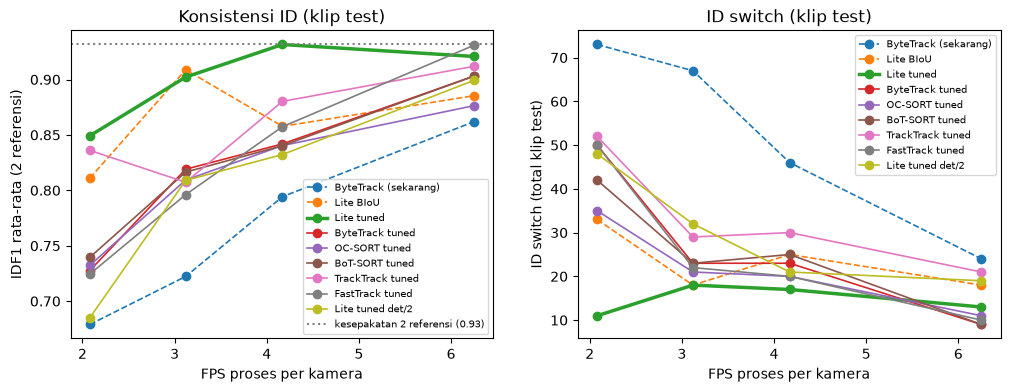

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
show = ["ByteTrack (sekarang)", "Lite BIoU"] + [k for k in TUNED]
for name in show:
    g = test_sum[test_sum.tracker == name].sort_values("fps")
    if not len(g):
        continue
    style = "--" if name in ("ByteTrack (sekarang)", "Lite BIoU") else "-"
    ax[0].plot(g.fps, g.IDF1, style, marker="o", label=name, lw=2.5 if name == BEST else 1.2)
    ax[1].plot(g.fps, g["ID switch"], style, marker="o", label=name, lw=2.5 if name == BEST else 1.2)
agree = ref_agree[ref_agree.set == "test"]["IDF1 ByteTrack vs OC-SORT"].mean()
ax[0].axhline(agree, ls=":", c="gray", label=f"kesepakatan 2 referensi ({agree:.2f})")
ax[0].set_xlabel("FPS proses per kamera"); ax[0].set_ylabel("IDF1 rata-rata (2 referensi)"); ax[0].set_title("Konsistensi ID (klip test)")
ax[1].set_xlabel("FPS proses per kamera"); ax[1].set_ylabel("ID switch (total klip test)"); ax[1].set_title("ID switch (klip test)")
ax[0].legend(fontsize=7); ax[1].legend(fontsize=7)
savefig("penilaian_per_fps")

## 5. Ablasi Lite tracker
Mulai dari `Lite tuned`, lalu satu opsi dimatikan atau dibalik. Kalau IDF1 turun saat sebuah opsi dimatikan, berarti opsi itu membantu.

In [21]:
if "Lite tuned" in TUNED:
    base = TUNED["Lite tuned"]
    P = base.params
    abl = [base]
    for key, off, label in [("oru", False, "tanpa ORU"), ("ocr", False, "tanpa OCR"), ("nsa", not P.get("nsa", True), "NSA dibalik"),
                            ("cost", "iou" if P.get("cost") == "diou" else "diou", "biaya dibalik (IoU/DIoU)"),
                            ("max_h_ratio", 0.0 if P.get("max_h_ratio", 0) else 1.6, "gerbang rasio tinggi dibalik"),
                            ("buffers", (0.0,), "tanpa box diperbesar")]:
        abl.append(base.with_params(name=f"Lite tuned, {label}", **{key: off}))
    abl.append(replace(base, name="Lite tuned, hanya orang skor >= 0,5", person_min=0.5))
    abl_df = eval_specs(abl, TEST_CACHES, REFS_TEST, TEST_FPS)
    abl_sum = abl_df.groupby("tracker").agg(IDF1=("IDF1", "mean"), **{"ID switch": ("ID switch", "sum"), "cakupan": ("cakupan", "mean")})
    abl_sum["selisih IDF1"] = abl_sum.IDF1 - abl_sum.loc["Lite tuned", "IDF1"]
    display(abl_sum.sort_values("IDF1", ascending=False).round(4))
    RESULTS["ablation"] = abl_sum.reset_index().to_dict("records")

,IDF1,ID switch,cakupan,selisih IDF1
tracker,,,,
"Lite tuned, NSA dibalik",0.9012,65,0.9564,0.0003
Lite tuned,0.9009,59,0.9570,0.0000
"Lite tuned, tanpa OCR",0.9009,59,0.9570,0.0000
"Lite tuned, tanpa ORU",0.9009,59,0.9570,0.0000
"Lite tuned, tanpa box diperbesar",0.9009,59,0.9570,0.0000
"Lite tuned, biaya dibalik (IoU/DIoU)",0.8885,85,0.9544,-0.0124
"Lite tuned, gerbang rasio tinggi dibalik",0.8381,118,0.9497,-0.0628
"Lite tuned, hanya orang skor >= 0,5",0.8296,71,0.9052,-0.0713


## 6. Perkiraan kapasitas kamera
Beban per kamera per detik = deteksi per detik x waktu detektor + decode video + tracker. Angka ini untuk **satu jalur proses** di mesin ini. Decode dihitung dari satu klip, karena video H.264 harus di-decode di setiap frame walau yang dianalisis hanya beberapa frame per detik.

In [22]:
dec = decode_cost(VIDEO_DIR / f"{TEST_CLIPS[0]}.mp4", seconds=5 if QUICK else 10)
print(f"decode {TEST_CLIPS[0]} ({dec['width']}x{dec['height']}): {dec['ms_per_video_second']:.0f} ms per detik video")
rows = []
for fps in TEST_FPS:
    for n in (1, 2):
        cap = capacity(DET_MS, fps, n, decode_ms_per_video_sec=dec["ms_per_video_second"], track_ms=0.5)
        rows.append({"FPS proses": fps, "detektor tiap N frame": n, "deteksi/detik": cap["det_per_sec"],
                     "ms beban per kamera per detik": round(cap["ms_per_camera_second"], 1),
                     "kamera per jalur": round(cap["cameras_per_worker"], 1),
                     f"jalur untuk {TARGET_CAMERAS} kamera": int(np.ceil(TARGET_CAMERAS / max(cap["cameras_per_worker"], 1e-6)))})
cap_df = pd.DataFrame(rows)
display(cap_df)
need_ms = 1000 / (TARGET_CAMERAS * 4)
print(f"Supaya {TARGET_CAMERAS} kamera x 4 deteksi/detik muat di 1 jalur, detektor harus <= {need_ms:.0f} ms per frame "
      f"(sekarang {DET_MS:.0f} ms, belum termasuk decode). Tracker sendiri di bawah 1 ms per frame.")
RESULTS["capacity"] = rows
RESULTS["decode"] = dec
save_results()

decode v02_momen_013 (2688x1520): 84 ms per detik video


,FPS proses,detektor tiap N frame,deteksi/detik,ms beban per kamera per detik,kamera per jalur,jalur untuk 12 kamera
0,2,1,2.0,177.9,5.6,3
1,2,2,1.0,131.2,7.6,2
2,3,1,3.0,225.0,4.4,3
3,3,2,1.5,155.1,6.4,2
4,4,1,4.0,272.2,3.7,4
5,4,2,2.0,178.9,5.6,3
6,6,1,6.0,366.5,2.7,5
7,6,2,3.0,226.5,4.4,3


Supaya 12 kamera x 4 deteksi/detik muat di 1 jalur, detektor harus <= 21 ms per frame (sekarang 47 ms, belum termasuk decode). Tracker sendiri di bawah 1 ms per frame.


## 7. Simpan hasil
Semua spec hasil tuning ditulis ke `configs/tracker_tuned.json` (dibaca aplikasi perbandingan dan notebook lain). Kalau `Lite tuned` berubah, salin juga parameternya ke `LITE_TUNED_PARAMS` di `src/object_tracking/integration.py`, karena file itulah yang dipasang ke pipeline utama. Sel ini mencetak teks yang tinggal ditempel.

In [23]:
SAVE = True       # False = jangan timpa configs/tracker_tuned.json
meta = {}
for k, s in TUNED.items():
    o = overall.loc[k] if k in overall.index else None
    tr = next((r for r in tune_rows if r["nama"] == k), {})
    meta[k] = {"skor tuned (tuning)": tr.get("skor tuned (tuning)"), "skor bawaan (tuning)": tr.get("skor bawaan (tuning)"),
               "IDF1 test": None if o is None else float(o.IDF1), "ID switch test": None if o is None else int(o["ID switch"])}
if SAVE:
    save_tuned(TUNED, meta, best=BEST, info={"run": RUN_ID, "tune_clips": TUNE_CLIPS, "test_clips": TEST_CLIPS,
                                              "fps": TEST_FPS, "detector": DET_MODEL.name})
    print("tersimpan:", TUNED_PATH)
if "Lite tuned" in TUNED:
    lt = TUNED["Lite tuned"]
    print("\nUntuk integration.py:")
    print("LITE_TUNED_PARAMS =", {k: (tuple(v) if isinstance(v, list) else v) for k, v in lt.params.items()})
    print("LITE_TUNED_INPUT =", {"person_min": lt.person_min, "nms_iou": lt.nms_iou})
RESULTS["best"] = BEST
save_results()

tersimpan: /Users/rdrusdiati/Documents/GitHub/object-tracking/configs/tracker_tuned.json

Untuk integration.py:
LITE_TUNED_PARAMS = {'high_thresh': 0.537, 'low_thresh': 0.2, 'min_iou': 0.155, 'min_iou_low': 0.41, 'buffers': (0.0,), 'max_lost_sec': 3.891, 'std_vel': 0.785, 'std_pos': 0.051, 'lost_velocity_decay_sec': 1.715, 'confirm_hits': 2, 'nsa': False, 'oru': False, 'ocr': False, 'cost': 'iou', 'max_h_ratio': 0.0, 'new_thresh': 0.577}
LITE_TUNED_INPUT = {'person_min': 0.05, 'nms_iou': 0.6}
